# 05 · Results and the shortlist

What the models are worth, what they are reading, and the ranked plant compounds that come out of
them. Nothing is fitted here: the models arrive tuned and calibrated from 04 and every number below
is a read-once evaluation or a prediction on compounds that have never been measured.

| section | question |
|---|---|
| 1 | how well does it rank, on both held-out sets |
| 2 | which should lead, and why that is a decision rather than a fact |
| 3 | what the model is reading |
| 4 | the screening set, and how far it sits from anything the model has seen |
| 5 | the ranked shortlist per pathogen, with diversity selection |
| 6 | what this does not support |

Code: `pipeline/models.py`, `pipeline/featureset.py`, `pipeline/ledger.py`.

## 0. Settings

In [1]:
import os
import pickle
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from pipeline import curation, data, featureset, features, ledger, models, viz

viz.use_style()
pd.set_option("display.width", 220)

RESULTS = Path(os.environ.get("ETHNOHACK_RESULTS_DIR", ROOT / "results"))
RESULTS.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "pathogens": curation.PATHOGENS,
    "candidate_pool": int(os.environ.get("ETHNOHACK_POOL", 500)),
    "shortlist_size": int(os.environ.get("ETHNOHACK_SHORTLIST", 50)),
    "domain_sample": 3000,
    "domain_cutoff_percentile": 25,
    "seed": 0,
}
pd.Series(CONFIG, name="value").to_frame()

,value
pathogens,"[Staphylococcus aureus, Escherichia coli, Myco..."
candidate_pool,500
shortlist_size,50
domain_sample,3000
domain_cutoff_percentile,25
seed,0


## 1. How well it ranks

Both held-out sets, side by side, as 04 scored them. The scaffold test set holds out whole
Bemis-Murcko scaffolds from the same mostly-synthetic chemistry the model trained on. The plant
holdout is every plant-derived compound that carries a measurement, kept out of training entirely.

In [2]:
fitted = {}
for organism in CONFIG["pathogens"]:
    slug = curation.slug(organism)
    fitted[organism] = pickle.loads((data.PROCESSED / f"04_models_{slug}.pkl").read_bytes())

rows = []
for organism in CONFIG["pathogens"]:
    slug = curation.slug(organism)
    for name in ("test", "plant"):
        scored = pd.read_parquet(data.PROCESSED / f"04_scores_{slug}_{name}.parquet")
        metrics = models.evaluate(scored.label.to_numpy(), scored.score.to_numpy())
        metrics["distinct scores, raw"] = int(scored.score.nunique())
        metrics["distinct scores, calibrated"] = int(scored.score_calibrated.nunique())
        lo, hi = models.bootstrap_metric(
            scored.label.to_numpy(), scored.score.to_numpy(),
            models.roc_auc_score, seed=CONFIG["seed"]
        )
        plo, phi = models.bootstrap_metric(
            scored.label.to_numpy(), scored.score.to_numpy(),
            lambda a, b: models.precision_at(a, b, 0.05), seed=CONFIG["seed"]
        )
        rows.append({
            "pathogen": organism,
            "set": "scaffold test" if name == "test" else "plant holdout",
            "n": metrics["n"],
            "base rate": metrics["base_rate"],
            "AUROC": metrics["auroc"],
            "AUROC lo": lo,
            "AUROC hi": hi,
            "precision top 5%": metrics["precision_top_5pct"],
            "precision lo": plo,
            "precision hi": phi,
            "enrichment top 5%": metrics["enrichment_top_5pct"],
        })
headline = pd.DataFrame(rows).set_index(["pathogen", "set"])
headline.style.format("{:.3f}", subset=[c for c in headline.columns if c != "n"])

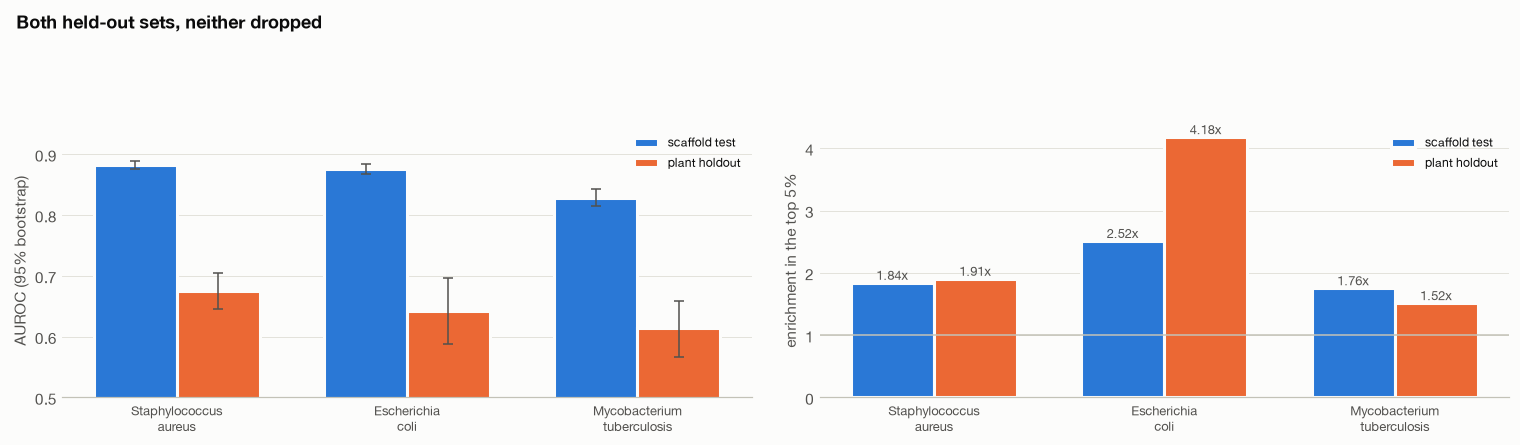

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
x = np.arange(len(CONFIG["pathogens"]))
width = 0.36
for i, name in enumerate(("scaffold test", "plant holdout")):
    block = [headline.loc[(o, name)] for o in CONFIG["pathogens"]]
    auroc = [b["AUROC"] for b in block]
    lo = [b["AUROC"] - b["AUROC lo"] for b in block]
    hi = [b["AUROC hi"] - b["AUROC"] for b in block]
    axes[0].bar(x + (i - 0.5) * width, auroc, width=width, yerr=[lo, hi], capsize=3,
                color=viz.SERIES[i], edgecolor=viz.SURFACE, linewidth=2,
                error_kw=dict(ecolor=viz.INK_SECONDARY, lw=1), label=name)
    enrich = [b["enrichment top 5%"] for b in block]
    axes[1].bar(x + (i - 0.5) * width, enrich, width=width, color=viz.SERIES[i],
                edgecolor=viz.SURFACE, linewidth=2, label=name)
    for xi, v in zip(x + (i - 0.5) * width, enrich):
        axes[1].text(xi, v, f"{v:.2f}x", ha="center", va="bottom", fontsize=8.5,
                     color=viz.INK_SECONDARY)
axes[0].set_ylim(0.5, 0.95)
axes[0].set_ylabel("AUROC (95% bootstrap)")
axes[1].axhline(1.0, color=viz.AXIS, linewidth=1)
axes[1].set_ylabel("enrichment in the top 5%")
for ax in axes:
    ax.set_xticks(x, [o.replace(" ", "\n") for o in CONFIG["pathogens"]], fontsize=8.5)
    ax.grid(axis="x", visible=False)
    ax.legend(fontsize=8)
fig.suptitle("Both held-out sets, neither dropped", x=0.02, ha="left", fontweight="bold")
viz.save(fig, "05_held_out")
plt.show()

## 2. Which number should lead

The two sets disagree by a wide margin and the gap is not noise, so one of them has to lead in the
pitch. This section makes the argument and leaves the choice, because it is a question about what
the project claims rather than about what the data says.

**The case for the scaffold test set.** It is the evaluation the project settled on. It is
comparable with the bioactivity-prediction literature, which almost always reports a scaffold or
random split. It rests on thousands of compounds rather than hundreds, so its intervals are tight.

**The case for the plant holdout.** It is the only partition made of the chemistry the deliverable
is drawn from. 03 measured how far each held-out set sits from training: the scaffold test set has
a median nearest-neighbour Tanimoto around 0.67 to 0.70 with roughly a fifth of compounds above
0.80, while the plant holdout sits at 0.39 to 0.47. A scaffold split holds out scaffolds, not
analogues, so a congeneric series spreads across several scaffolds and lands on both sides. The
higher scaffold-test AUROC is therefore partly an analogue-proximity artefact, and the plant number
is what a wet lab should expect.

**What we would say.** Lead with the plant holdout, report the scaffold test set beside it, and
say plainly that the difference is a distance effect rather than two attempts at the same
measurement. The cost of leading with the higher number is that the first serious reader finds the
gap themselves.

In [4]:
gap = pd.DataFrame({
    "scaffold test AUROC": [headline.loc[(o, "scaffold test"), "AUROC"] for o in CONFIG["pathogens"]],
    "plant holdout AUROC": [headline.loc[(o, "plant holdout"), "AUROC"] for o in CONFIG["pathogens"]],
}, index=CONFIG["pathogens"])
gap["difference"] = gap["scaffold test AUROC"] - gap["plant holdout AUROC"]
gap["intervals overlap"] = [
    not (headline.loc[(o, "plant holdout"), "AUROC hi"]
         < headline.loc[(o, "scaffold test"), "AUROC lo"])
    for o in CONFIG["pathogens"]
]
gap.rename_axis("pathogen").style.format("{:.3f}", subset=gap.columns[:3])

,scaffold test AUROC,plant holdout AUROC,difference,intervals overlap
pathogen,,,,
Staphylococcus aureus,0.883,0.675,0.207,False
Escherichia coli,0.876,0.641,0.235,False
Mycobacterium tuberculosis,0.828,0.614,0.214,False


## 3. What the model is reading

Feature importance for the biological reading the team asked for, by **permutation** rather than by
impurity. Impurity importance systematically inflates continuous features against binary ones, and
comparing a block of 14 continuous descriptors with 2,048 binary bits is exactly the case where
that bias decides the answer. Permutation importance asks a question that is fair to both: shuffle
these columns, how much AUROC is lost.

Two scales are measured. The whole descriptor block against the whole fingerprint block, which
says where the signal lives, and then each descriptor on its own, which is the part a chemist can
read.

In [5]:
def permutation_drop(model, X, y, columns, repeats=5, seed=0):
    rng = np.random.default_rng(seed)
    base = models.roc_auc_score(y, model.predict_proba(X)[:, 1])
    drops = []
    for _ in range(repeats):
        shuffled = X.copy()
        order = rng.permutation(len(shuffled))
        shuffled[:, columns] = shuffled[order][:, columns]
        drops.append(base - models.roc_auc_score(y, model.predict_proba(shuffled)[:, 1]))
    return float(np.mean(drops)), float(np.std(drops))


block_rows, named_rows = [], []
n_desc = len(featureset.DESCRIPTOR_NAMES)
for organism in CONFIG["pathogens"]:
    payload = fitted[organism]
    feature_name = payload["feature_set"]
    slug = curation.slug(organism)
    bundle = featureset.load(f"03_features_{slug}")
    frame = pd.read_parquet(data.PROCESSED / f"03_splits_{slug}.parquet")
    validation = np.where(frame.partition.eq("validation").to_numpy())[0]
    X = featureset.matrix(bundle, feature_name)[validation]
    y = bundle["label"][validation]

    if feature_name == "hybrid":
        bits = np.arange(X.shape[1] - n_desc)
        descs = np.arange(X.shape[1] - n_desc, X.shape[1])
    elif feature_name == "descriptors":
        bits, descs = np.array([], dtype=int), np.arange(X.shape[1])
    else:
        bits, descs = np.arange(X.shape[1]), np.array([], dtype=int)

    row = {"pathogen": organism, "feature set": feature_name}
    for label, columns in [("fingerprint bits", bits), ("physicochemical block", descs)]:
        if len(columns):
            mean, sd = permutation_drop(payload["model_object"], X, y, columns,
                                        seed=CONFIG["seed"])
            row[f"AUROC lost, {label}"] = mean
            row[f"sd, {label}"] = sd
        else:
            row[f"AUROC lost, {label}"] = np.nan
            row[f"sd, {label}"] = np.nan
    block_rows.append(row)

    if len(descs):
        for offset, name in enumerate(featureset.DESCRIPTOR_NAMES):
            mean, _ = permutation_drop(payload["model_object"], X, y,
                                       np.array([descs[offset]]), repeats=3,
                                       seed=CONFIG["seed"])
            named_rows.append({"pathogen": organism, "descriptor": name, "AUROC lost": mean})
    del bundle, X
    print(f"  {organism}: permutation importance done", flush=True)

blocks = pd.DataFrame(block_rows).set_index("pathogen")
display(blocks.style.format("{:.4f}", subset=[c for c in blocks.columns if c != "feature set"]))

  Staphylococcus aureus: permutation importance done


  Escherichia coli: permutation importance done


  Mycobacterium tuberculosis: permutation importance done


,feature set,"AUROC lost, fingerprint bits","sd, fingerprint bits","AUROC lost, physicochemical block","sd, physicochemical block"
pathogen,,,,,
Staphylococcus aureus,hybrid,0.2538,0.0037,0.1695,0.0029
Escherichia coli,hybrid,0.2971,0.0047,0.1320,0.0053
Mycobacterium tuberculosis,morgan,0.3373,0.0050,nan,nan


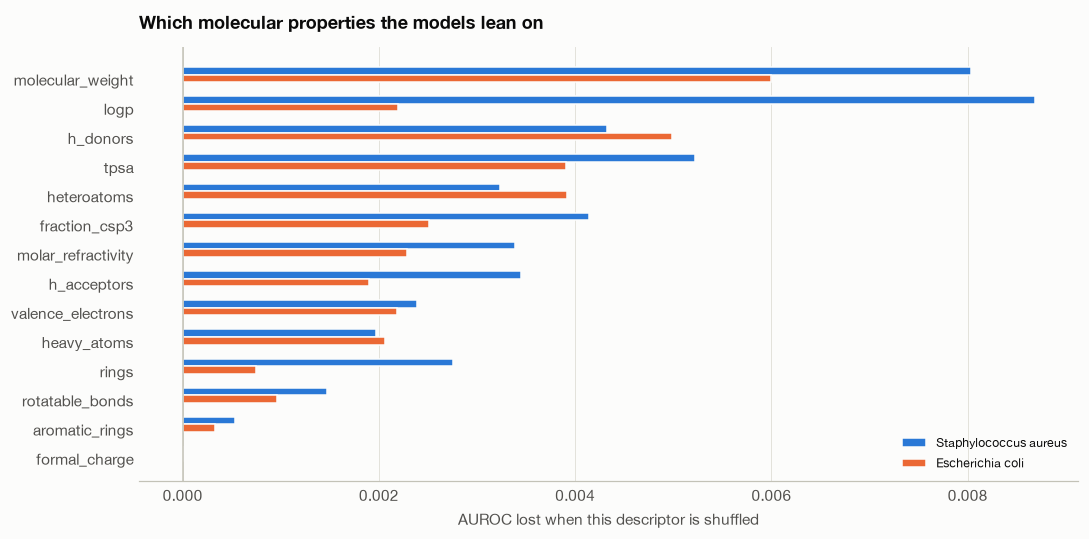

pathogen,Escherichia coli,Staphylococcus aureus
descriptor,,
molecular_weight,0.0060,0.0080
logp,0.0022,0.0087
h_donors,0.0050,0.0043
tpsa,0.0039,0.0052
heteroatoms,0.0039,0.0032
fraction_csp3,0.0025,0.0041
molar_refractivity,0.0023,0.0034
h_acceptors,0.0019,0.0035
valence_electrons,0.0022,0.0024


In [6]:
named = pd.DataFrame(named_rows)
if len(named):
    pivot = named.pivot(index="descriptor", columns="pathogen", values="AUROC lost")
    pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(10, 5))
    y_pos = np.arange(len(pivot))
    width = 0.26
    for i, organism in enumerate(CONFIG["pathogens"]):
        if organism in pivot.columns:
            ax.barh(y_pos + (i - 1) * width, pivot[organism], height=width,
                    color=viz.SERIES[i], edgecolor=viz.SURFACE, linewidth=1, label=organism)
    ax.set_yticks(y_pos, pivot.index)
    ax.invert_yaxis()
    ax.axvline(0, color=viz.AXIS, linewidth=1)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("AUROC lost when this descriptor is shuffled")
    ax.legend(fontsize=8)
    ax.set_title("Which molecular properties the models lean on")
    viz.save(fig, "05_feature_importance")
    plt.show()
    display(pivot.round(4))
else:
    print("No model uses the descriptor block, so there is no named ranking to show.")

## 4. The screening set

Every plant compound LOTUS reports that has no measured antibacterial activity in our tables. The
count here is **compounds**, deduplicated by InChIKey skeleton the way every other stage of this
pipeline is. The raw structure count is larger because stereoisomers and salt forms each get their
own row, and ranking those separately would put the same molecule on the shortlist several times.

In [7]:
plant = pd.read_parquet(data.PROCESSED / "01_plant_structures.parquet")
plant["skeleton"] = plant.structure_inchikey.str.split("-").str[0]

labelled = set()
for organism in CONFIG["pathogens"]:
    slug = curation.slug(organism)
    labelled |= set(pd.read_parquet(
        data.PROCESSED / f"02_labelled_{slug}.parquet", columns=["skeleton"]
    ).skeleton)

plant["smiles_length"] = plant.structure_smiles.str.len()
candidates = (
    plant.sort_values(["skeleton", "smiles_length", "structure_smiles"])
    .drop_duplicates("skeleton")
    .loc[lambda d: ~d.skeleton.isin(labelled)]
    .reset_index(drop=True)
)
pd.Series({
    "reported structures in LOTUS (plants)": len(plant),
    "distinct compounds (InChIKey skeleton)": plant.skeleton.nunique(),
    "already measured against one of our three pathogens": len(labelled & set(plant.skeleton)),
    "screening set, never measured": len(candidates),
    "with an NPClassifier pathway": int(candidates.np_pathway.notna().sum()),
}, name="value").to_frame()

,value
reported structures in LOTUS (plants),153745
distinct compounds (InChIKey skeleton),99556
already measured against one of our three pathogens,2053
"screening set, never measured",97503
with an NPClassifier pathway,94393


In [8]:
start = time.time()
screen_table = candidates.rename(columns={"structure_smiles": "canonical_smiles"})
screen_table = screen_table[["skeleton", "canonical_smiles", "np_pathway",
                             "np_superclass", "np_class"]]
NO_LABEL = -1
screen_table["label"] = NO_LABEL
screen_table["from_plant"] = True
screen_table["family"] = np.nan
screen_bundle = featureset.build(screen_table)
print(f"featurised {len(screen_bundle['skeleton']):,} candidates in {time.time() - start:.0f}s")
assert set(np.unique(screen_bundle["label"])) == {NO_LABEL}, (
    "the screening set must carry no real labels: these compounds have never been measured, "
    "and any metric computed against them would be meaningless"
)

annotation = screen_table.set_index("skeleton")
keep = pd.Index(screen_bundle["skeleton"])
screen_meta = annotation.loc[keep, ["canonical_smiles", "np_pathway", "np_superclass", "np_class"]]
pathways = screen_meta.np_pathway.fillna("(not classified)").value_counts(normalize=True)
pathways.head(8).mul(100).round(1).rename("share of screening set (%)").to_frame()

    featurised 20,000/97,503


    featurised 40,000/97,503


    featurised 60,000/97,503


    featurised 80,000/97,503


featurised 97,503 candidates in 49s


,share of screening set (%)
np_pathway,
Terpenoids,45.8
Shikimates and Phenylpropanoids,25.5
Alkaloids,10.4
Polyketides,5.3
Fatty acids,4.8
(not classified),3.2
Alkaloids $ Terpenoids,1.8
Amino acids and Peptides,1.1


## 5. Scoring, applicability domain and the shortlist

Three steps per pathogen. Score everything, keep the top `candidate_pool`, then choose
`shortlist_size` from that pool by farthest-point sampling so the compounds that go to a chemist
are not fifty variations on one skeleton.

**Ranking uses the raw model score; the calibrated probability is what gets displayed.** Isotonic
regression is a step function and collapses the whole screening set onto a few dozen levels, so
ranking on it would cut the top 500 out of one flat tier by row order rather than by the model.
Isotonic is monotone, so the two orderings agree wherever the raw scores differ. The printed line
below shows how many distinct values each carries, which is the size of the problem being avoided.

The applicability domain travels with every candidate. These compounds were never tested, so they
sit further from the training chemistry than even the plant holdout did, and a confident score on a
compound unlike anything the model has seen is the least trustworthy output this pipeline can
produce.

In [9]:
DOMAIN_CUTOFF = None


def nearest_tanimoto(query, reference, chunk=3000):
    best = np.zeros(len(query))
    for start in range(0, len(reference), chunk):
        block = reference[start:start + chunk]
        inter = query @ block.T
        union = query.sum(1)[:, None] + block.sum(1)[None, :] - inter
        best = np.maximum(best, (inter / np.maximum(union, 1)).max(axis=1))
    return best


def farthest_point(matrix, count, seed=0):
    chosen = [int(np.random.default_rng(seed).integers(len(matrix)))]
    inter = matrix @ matrix[chosen[0]]
    union = matrix.sum(1) + matrix[chosen[0]].sum() - inter
    nearest = inter / np.maximum(union, 1)
    while len(chosen) < min(count, len(matrix)):
        pick = int(np.argmin(nearest))
        chosen.append(pick)
        inter = matrix @ matrix[pick]
        union = matrix.sum(1) + matrix[pick].sum() - inter
        nearest = np.maximum(nearest, inter / np.maximum(union, 1))
    return chosen


screen_morgan = featureset.unpack_morgan(screen_bundle["morgan"])
needed = sorted({fitted[o]["feature_set"] for o in CONFIG["pathogens"]})
screen_matrices = featureset.matrices(screen_bundle, needed)
print(f"built {needed} for {len(screen_bundle['skeleton']):,} candidates")

plant_distances = []
for organism in CONFIG["pathogens"]:
    slug = curation.slug(organism)
    bundle = featureset.load(f"03_features_{slug}")
    frame = pd.read_parquet(data.PROCESSED / f"03_splits_{slug}.parquet")
    morgan = featureset.unpack_morgan(bundle["morgan"])
    train_i = np.where(frame.partition.eq("train").to_numpy())[0]
    plant_i = np.where(frame.partition.eq("plant").to_numpy())[0]
    plant_distances.append(nearest_tanimoto(morgan[plant_i], morgan[train_i]))
    del morgan, bundle
plant_distances = np.concatenate(plant_distances)
DOMAIN_CUTOFF = float(np.percentile(plant_distances, CONFIG["domain_cutoff_percentile"]))
print(f"plant holdout nearest-neighbour Tanimoto: median {np.median(plant_distances):.3f}, "
      f"10th pct {np.percentile(plant_distances, 10):.3f}")
print(f"applicability-domain cutoff set to the {CONFIG['domain_cutoff_percentile']}th percentile "
      f"of that distribution: {DOMAIN_CUTOFF:.3f}")

shortlists, domain_rows = {}, []
rng = np.random.default_rng(CONFIG["seed"])
for organism in CONFIG["pathogens"]:
    payload = fitted[organism]
    feature_name = payload["feature_set"]
    X = screen_matrices[feature_name]
    scores = payload["model_object"].predict_proba(X)[:, 1]
    displayed = payload["calibrator"].predict_proba(X)[:, 1]

    train_bundle = featureset.load(f"03_features_{curation.slug(organism)}")
    train_frame = pd.read_parquet(
        data.PROCESSED / f"03_splits_{curation.slug(organism)}.parquet"
    )
    train_index = np.where(train_frame.partition.eq("train").to_numpy())[0]
    train_morgan = featureset.unpack_morgan(train_bundle["morgan"])[train_index]
    del train_bundle

    probe = rng.choice(len(screen_morgan), CONFIG["domain_sample"], replace=False)
    sampled_distance = nearest_tanimoto(screen_morgan[probe], train_morgan)
    domain_rows.append({
        "pathogen": organism,
        "median nearest Tanimoto (screening set)": float(np.median(sampled_distance)),
        "share in domain": float((sampled_distance >= DOMAIN_CUTOFF).mean()),
    })

    top = np.argsort(-scores)[: CONFIG["candidate_pool"]]
    top_distance = nearest_tanimoto(screen_morgan[top], train_morgan)
    picked = farthest_point(screen_morgan[top], CONFIG["shortlist_size"], CONFIG["seed"])
    chosen = top[picked]

    frame = pd.DataFrame({
        "selection_order": np.arange(1, len(chosen) + 1),
        "skeleton": screen_bundle["skeleton"][chosen],
        "canonical_smiles": screen_meta.canonical_smiles.to_numpy()[chosen],
        "predicted_probability": displayed[chosen],
        "ranking_score": scores[chosen],
        "nearest_training_tanimoto": top_distance[picked],
        "in_applicability_domain": top_distance[picked] >= DOMAIN_CUTOFF,
        "fingerprint_twin_of_training": top_distance[picked] >= 0.99,
        "np_pathway": screen_meta.np_pathway.to_numpy()[chosen],
        "np_superclass": screen_meta.np_superclass.to_numpy()[chosen],
    })
    frame = frame.sort_values("ranking_score", ascending=False).reset_index(drop=True)
    frame.insert(0, "rank", np.arange(1, len(frame) + 1))
    assert frame.ranking_score.is_monotonic_decreasing, "rank must follow the ranking score"
    shortlists[organism] = frame
    print(f"{organism}: scored {len(scores):,} "
          f"({len(np.unique(scores)):,} distinct raw vs {len(np.unique(displayed)):,} calibrated), "
          f"pool {len(top)}, shortlist {len(chosen)}", flush=True)
    del train_morgan
domain = pd.DataFrame(domain_rows).set_index("pathogen")
domain.style.format({"median nearest Tanimoto (screening set)": "{:.3f}",
                     "share in domain": "{:.1%}"})

built ['hybrid', 'morgan'] for 97,503 candidates


plant holdout nearest-neighbour Tanimoto: median 0.446, 10th pct 0.272
applicability-domain cutoff set to the 25th percentile of that distribution: 0.333


Staphylococcus aureus: scored 97,503 (3,664 distinct raw vs 197 calibrated), pool 500, shortlist 50


Escherichia coli: scored 97,503 (2,731 distinct raw vs 158 calibrated), pool 500, shortlist 50


Mycobacterium tuberculosis: scored 97,503 (7,375 distinct raw vs 324 calibrated), pool 500, shortlist 50


,median nearest Tanimoto (screening set),share in domain
pathogen,,
Staphylococcus aureus,0.349,56.1%
Escherichia coli,0.337,51.6%
Mycobacterium tuberculosis,0.297,34.1%


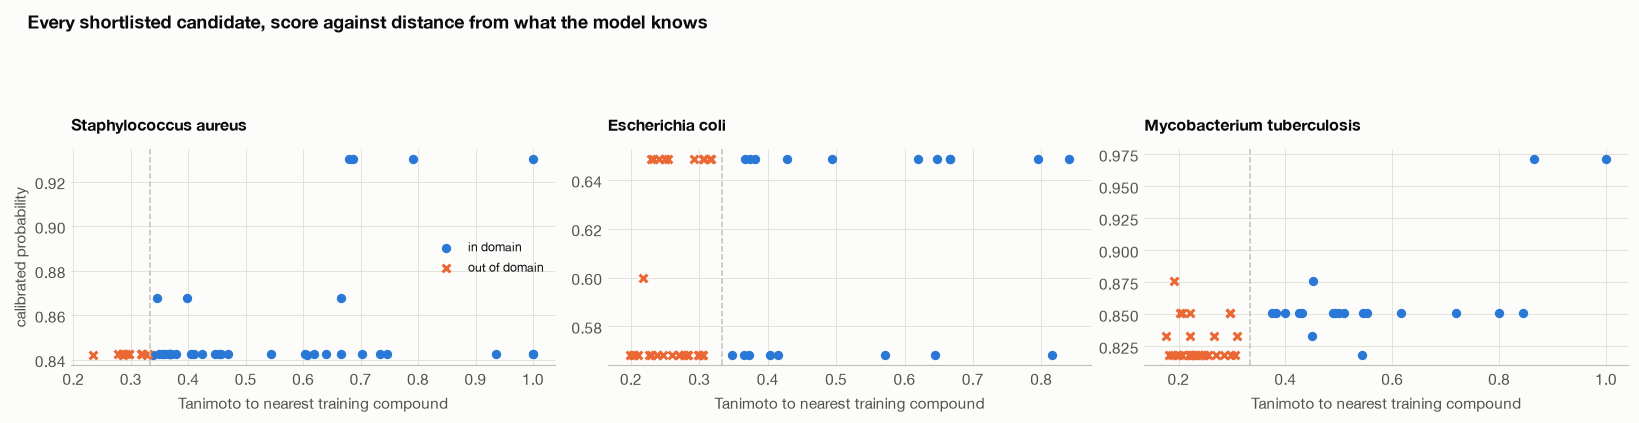

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, organism in zip(axes, CONFIG["pathogens"]):
    frame = shortlists[organism]
    inside = frame[frame.in_applicability_domain]
    outside = frame[~frame.in_applicability_domain]
    ax.scatter(inside.nearest_training_tanimoto, inside.predicted_probability,
               s=26, color=viz.SERIES[0], label="in domain")
    ax.scatter(outside.nearest_training_tanimoto, outside.predicted_probability,
               s=26, color=viz.SERIES[1], marker="x", label="out of domain")
    ax.axvline(DOMAIN_CUTOFF, color=viz.AXIS, linewidth=1, linestyle="--")
    ax.set_xlabel("Tanimoto to nearest training compound")
    ax.set_title(organism, fontsize=10.5)
axes[0].set_ylabel("calibrated probability")
axes[0].legend(fontsize=8)
fig.suptitle("Every shortlisted candidate, score against distance from what the model knows",
             x=0.02, ha="left", fontweight="bold")
viz.save(fig, "05_applicability_domain")
plt.show()

### Candidates the model has effectively already seen

A candidate can be absent from every label table and still be indistinguishable from a training
compound, because two different molecules can share a Morgan fingerprint. The flag below counts
them, and they are worth looking at rather than quietly dropping.

In [11]:
twins = []
for organism in CONFIG["pathogens"]:
    frame = shortlists[organism]
    twins.append({
        "pathogen": organism,
        "shortlisted": len(frame),
        "fingerprint-identical to a training compound": int(frame.fingerprint_twin_of_training.sum()),
        "median distance to training": float(frame.nearest_training_tanimoto.median()),
    })
display(pd.DataFrame(twins).set_index("pathogen").style.format(
    {"median distance to training": "{:.3f}"}))

example = None
for organism in CONFIG["pathogens"]:
    hit = shortlists[organism][shortlists[organism].fingerprint_twin_of_training]
    if len(hit):
        example = (organism, hit.iloc[0])
        break
if example is not None:
    organism, row = example
    print(f"Example, {organism}: {row.skeleton}")
    print(f"  {row.canonical_smiles}")
    print(f"  ranked {int(row['rank'])}, raw score {row.ranking_score:.3f}, "
          f"Tanimoto to nearest training compound {row.nearest_training_tanimoto:.3f}")

,shortlisted,fingerprint-identical to a training compound,median distance to training
pathogen,,,
Staphylococcus aureus,50,3,0.388
Escherichia coli,50,0,0.302
Mycobacterium tuberculosis,50,1,0.291


Example, Staphylococcus aureus: GFIDXEMAMVCCCW
  C1[C@H](OC2=C(C(=C(C(=C2C1=O)O)CC3=CC=CC=C3O)O)CC4=C(C=CC(=C4)CC5=C(C=CC(=C5)CC6=CC=CC=C6O)O)O)C7=CC=CC=C7
  ranked 3, raw score 0.860, Tanimoto to nearest training compound 1.000


These are real molecules absent from every label table, so the pipeline has not leaked. What they
show is a limit of the representation. A Morgan fingerprint at radius 2 records the substructure
environments present, not how many times a repeating one occurs, so a C9 alkyl chain and a C12
alkyl chain produce the same bits. The example above is a bis-quaternary ammonium surfactant whose
nearest training neighbours are longer-chain homologs of the same series, all labelled active.

Two consequences, and both belong in front of a chemist rather than buried. The model cannot
distinguish chain-length homologs at all, so a candidate flagged here is a recall of a known
active rather than a new idea. And the series it recalls is a quaternary ammonium surfactant,
which kills bacteria by disrupting membranes, works on almost anything, and is exactly the kind of
promiscuous hit a screening campaign is supposed to discard. That the model ranks them highly is
expected, and it is a reason to read the shortlist with a chemist rather than to act on the rank
order alone.

### Did the diversity step buy anything

Farthest-point sampling is supposed to spread the shortlist across chemical space. NPClassifier
gives an independent check that costs nothing, because the biosynthetic pathway is already on every
LOTUS record: if the shortlist collapses into one pathway while the pool it came from did not, the
projection is not buying diversity and the honest thing is to say so.

In [12]:
diversity_rows = []
for organism in CONFIG["pathogens"]:
    frame = shortlists[organism]
    share = frame.np_pathway.fillna("(not classified)").value_counts(normalize=True)
    diversity_rows.append({
        "pathogen": organism,
        "distinct pathways in shortlist": int(frame.np_pathway.nunique()),
        "largest pathway share": float(share.iloc[0]),
        "largest pathway": share.index[0],
        "distinct superclasses": int(frame.np_superclass.nunique()),
        "in applicability domain": int(frame.in_applicability_domain.sum()),
    })
diversity = pd.DataFrame(diversity_rows).set_index("pathogen")
display(diversity.style.format({"largest pathway share": "{:.0%}"}))

print("Screening set for comparison:")
print(screen_meta.np_pathway.fillna("(not classified)")
      .value_counts(normalize=True).head(5).mul(100).round(1).to_string())

,distinct pathways in shortlist,largest pathway share,largest pathway,distinct superclasses,in applicability domain
pathogen,,,,,
Staphylococcus aureus,7,44%,Shikimates and Phenylpropanoids,18,36
Escherichia coli,10,30%,Shikimates and Phenylpropanoids,20,19
Mycobacterium tuberculosis,10,40%,Alkaloids,21,20


Screening set for comparison:
np_pathway
Terpenoids                         45.8
Shikimates and Phenylpropanoids    25.5
Alkaloids                          10.4
Polyketides                         5.3
Fatty acids                         4.8


## 6. The shortlist

**Reading the columns.** `rank` orders the shortlist by `ranking_score`, the raw model score, so
rank 1 is the best-scoring candidate. `selection_order` is the order farthest-point sampling
picked them in, which carries no quality meaning at all: it starts from a seeded random candidate
and then repeatedly takes whichever remaining compound is least similar to everything chosen so
far. It is recorded because it is what produced this particular 50 out of the top
`candidate_pool`, not because a low number is better.

`predicted_probability` is the calibrated probability and it is deliberately coarse, taking only a
handful of distinct values across the 50, so two candidates showing the same probability are in
the same band rather than genuinely tied. `ranking_score` is what separates them.

In [13]:
written = []
for organism in CONFIG["pathogens"]:
    slug = curation.slug(organism)
    frame = shortlists[organism]
    path = RESULTS / f"shortlist_{slug}.csv"
    frame.to_csv(path, index=False)
    written.append({"pathogen": organism, "compounds": len(frame),
                    "path": str(path.relative_to(ROOT))})

    entry = ledger.record(
        f"shortlist_{slug}",
        {
            "task": f"{organism} MIC, whole organism",
            "model": fitted[organism]["model"],
            "feature_set": fitted[organism]["feature_set"],
            "screening_set": "LOTUS plant compounds, deduplicated by InChIKey skeleton, "
                             "never measured against the three pathogens",
            "candidate_pool": CONFIG["candidate_pool"],
            "shortlist_size": CONFIG["shortlist_size"],
            "diversity": "farthest-point sampling on Morgan fingerprints",
            "in_domain_tanimoto": DOMAIN_CUTOFF,
        },
        {
            "screened": len(screen_bundle["skeleton"]),
            "shortlisted": len(frame),
            "median_shortlist_probability": float(frame.predicted_probability.median()),
            "median_shortlist_tanimoto": float(frame.nearest_training_tanimoto.median()),
            "in_domain": int(frame.in_applicability_domain.sum()),
            "distinct_pathways": int(frame.np_pathway.nunique()),
            "plant_auroc": headline.loc[(organism, "plant holdout"), "AUROC"],
            "test_auroc": headline.loc[(organism, "scaffold test"), "AUROC"],
        },
        note="notebook 05 shortlist",
    )
    print(f"{organism}: ledger {entry['id']}")
display(pd.DataFrame(written).set_index("pathogen"))

preview = shortlists[CONFIG["pathogens"][0]].head(10).copy()
preview["canonical_smiles"] = preview.canonical_smiles.str.slice(0, 44) + "..."
preview[["rank", "selection_order", "skeleton", "canonical_smiles", "ranking_score",
         "predicted_probability", "nearest_training_tanimoto", "in_applicability_domain",
         "np_pathway"]]

Staphylococcus aureus: ledger 2026-11-04T04:17:41_shortlist_staphylococcus_aureus


Escherichia coli: ledger 2026-11-04T04:17:41_shortlist_escherichia_coli
Mycobacterium tuberculosis: ledger 2026-11-04T04:17:41_shortlist_mycobacterium_tuberculosis


,compounds,path
pathogen,,
Staphylococcus aureus,50,results/shortlist_staphylococcus_aureus.csv
Escherichia coli,50,results/shortlist_escherichia_coli.csv
Mycobacterium tuberculosis,50,results/shortlist_mycobacterium_tuberculosis.csv


,rank,selection_order,skeleton,canonical_smiles,ranking_score,predicted_probability,nearest_training_tanimoto,in_applicability_domain,np_pathway
0,1,12,NWXMGUDVXFXRIG,CC1(C2CC3C(C(=O)C(=C(C3(C(=O)C2=C(C4=C1C=CC=...,0.878571,0.930314,0.686567,True,Polyketides
1,2,11,UEDNENANFLMZJP,CCCCCCCCCCCC(=O)O[C@@H]1[C@@H]([C@H]([C@@H](...,0.862857,0.930314,0.678899,True,Fatty acids
2,3,16,GFIDXEMAMVCCCW,C1[C@H](OC2=C(C(=C(C(=C2C1=O)O)CC3=CC=CC=C3O...,0.860000,0.930314,1.000000,True,Shikimates and Phenylpropanoids
3,4,28,LXQOEJUMZZHKAH,CC(=CCC1(C(=C(C(=C(C1=O)C(=O)C)O)CC2=C(C(=C3...,0.848571,0.930314,0.790323,True,Polyketides
4,5,49,MNCFKANEQPGAHX,CC1=C(C=C2C(=C3CC(CC(=O)C3=C(C2=C1O)O)(C)O)C...,0.805000,0.867647,0.397059,True,Polyketides
5,6,33,LQOSVCHNBBWPJH,COC1=CC(=CC(=C1OC)OC)[C@H]2[C@@H]3[C@@H](COC...,0.804857,0.867647,0.345238,True,Shikimates and Phenylpropanoids
6,7,48,CJKYODJTBJDEJI,C[C@@H]1CC2=C(C(=C3C(=C2)C=C(C(=C3O)C4=C(C5=...,0.795714,0.867647,0.666667,True,Polyketides
7,8,20,LWTOHQGGAJCWFV,C[C@@H]1[C@H]([C@@H]([C@@H]([C@@H](O1)OC/2CC...,0.791429,0.842424,0.296875,False,Polyketides
8,9,4,VTNTUQUTQHRZTR,O=C1C(C(=O)CCC)=C(O)C(C(O)=C1CC=2C(O)=C(C(=O...,0.790000,0.842424,0.468750,True,Polyketides
9,10,10,DXSGQRROBDYCSJ,CC(=CCC1=C2C(=C(C3=C1O[C@@]45[C@H]6C[C@@H](C...,0.782857,0.842424,0.639175,True,NaN


## 7. What this does not support

**These are computational predictions, not evidence of activity.** Every compound on every
shortlist in this notebook is a structure that a model scored highly. Not one of them has been
tested against any bacterium by us. A high score is a reason to put a compound in a plate; it is
not a finding, not a claim of efficacy, and not a statement that the plant it comes from treats
any infection.

**Nothing here is medical advice and nothing here implies a dose.** The pipeline never handles
dosing, formulation, route, toxicity or human exposure, and the one compound property closest to
safety, haemolysis, is absent from the data entirely. Traditional use of a plant is how LOTUS came
to record its chemistry; it is not evidence that the plant, the extract or the compound treats
anything, and this notebook should never be cited as if it were.

**The honest performance number is the plant holdout, and it is modest.** 0.61 to 0.66 AUROC
depending on pathogen. The higher scaffold-split figure is partly an artefact of analogue
proximity, which section 2 sets out with the measurement behind it. Ranking at that level is
useful for ordering a synthesis queue and useless as a yes-or-no verdict on any single compound.

**Most of the screening set is outside the applicability domain.** The cutoff is derived rather
than chosen: it is the 25th percentile of the nearest-neighbour distribution of the plant holdout,
the most distant set on which we have a real performance number. Candidates below it carry an
out-of-domain flag and their scores should be read as little better than a guess, because the
model has seen nothing like them. The flag is in the output table for every candidate, not as a
summary.

### Limitations we measured rather than guessed at

- **Labels pool assay conditions.** ChEMBL reports MICs from different media, inocula, incubation
  times and bacterial strains, and the threshold is applied to all of them alike. A real MIC moves
  several-fold between protocols, so a compound labelled near the threshold is far less certain
  than one far from it, and nothing downstream models that uncertainty.
- **The positive class reflects publication bias.** 39% to 59% of measured compounds are labelled
  active depending on the pathogen, which is not what a screening library looks like. Compounds get published MICs
  because somebody expected them to work. The model therefore learns what gets tested and reported
  as much as what works, and that is the strongest reason to read precision at the head of the
  ranking rather than accuracy.
- **Between about 37% and 46% of the negative class rests on censored measurements alone**,
  depending on the pathogen: compounds only ever reported as inactive above some concentration,
  with no exact value anywhere. They are real measurements of failure and dropping them would
  destroy the negative class, but they carry less information than an exact number, and a model
  trained on them partly learns the concentrations people chose to test at. Notebook 02 section 4
  has the per-pathogen table.
- **The plant-compound link is literature-derived.** LOTUS records that a structure was reported
  from an organism. It does not say in what quantity, in which tissue, or whether the compound
  survives any preparation a person would actually use.
- **The model recovers known promiscuous actives, and cannot help doing so.** Some shortlisted
  compounds are fingerprint-identical to training compounds, because a Morgan fingerprint at
  radius 2 cannot tell a C9 alkyl chain from a C12 one. The series this surfaces most strongly is
  quaternary ammonium surfactants, which disrupt membranes indiscriminately and are the classic
  thing to discard from a screen rather than pursue. The flag is in the output table.
- **Whole-organism activity says nothing about mechanism.** 99.6% of our labels are growth
  inhibition of a living bacterium, so the models cannot say which protein a compound acts on, and
  no claim about mechanism should be read out of their feature importances.
- **Single compounds, not extracts.** Traditional plant medicine uses mixtures, and synergy
  between constituents is the part of the Track 2 brief that makes plant medicine interesting. It
  is not measurable from anything in this dataset and we have not attempted it.

### What would have to happen next

Broth microdilution MICs on the shortlisted compounds against the three pathogens, with a
haemolysis counter-screen, run by people with a laboratory. Until then the honest description of
this work is a ranked hypothesis list with its uncertainty attached, which is what the output
tables contain.

### Provenance

ChEMBL (CC BY-SA 3.0) for measured activity, LOTUS (CC0) for plant-compound occurrences, and the
GBIF backbone for the taxonomy that separates plants from fungal and bacterial metabolites. Every
figure in this notebook regenerates from `scripts/` plus notebooks 01 to 05, every run is recorded
in `results/LEDGER.md` with the commit and config behind it, and no data is committed to the
repository. Generative AI assistance was used throughout the build and is disclosed in the README.